#Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


#carga csv

In [2]:
from google.colab import files

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset cargado correctamente")
print("Dimensiones:", df.shape)

df.head()

Dataset cargado correctamente
Dimensiones: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Información general del dataset

In [4]:
print("Cantidad de filas y columnas:")
print(df.shape)

print("\nInformación de las columnas:")
df.info()

print("\nPrimeros 5 registros:")
display(df.head())

Cantidad de filas y columnas:
(7043, 21)

Información de las columnas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#Revision de datos faltantes

In [5]:
print("Valores nulos por columna:")
print(df.isnull().sum())

print("\nCantidad de registros duplicados:")
print(df.duplicated().sum())

Valores nulos por columna:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Cantidad de registros duplicados:
0


In [6]:
# Convertir TotalCharges a formato numérico

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Revisar valores faltantes
print("Valores faltantes en TotalCharges:")
print(df["TotalCharges"].isnull().sum())

# Eliminar registros con valores faltantes
df = df.dropna(subset=["TotalCharges"])

print("\nDimensiones después de la limpieza:")
print(df.shape)

Valores faltantes en TotalCharges:
11

Dimensiones después de la limpieza:
(7032, 21)


# Distribución de la variable objetivo

Churn
No     5163
Yes    1869
Name: count, dtype: int64


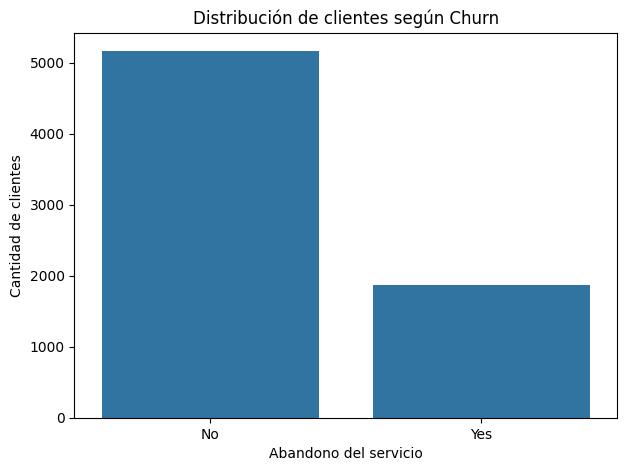

In [7]:
print(df["Churn"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Distribución de clientes según Churn")
plt.xlabel("Abandono del servicio")
plt.ylabel("Cantidad de clientes")

plt.show()

In [8]:
# Eliminar la columna customerID
df = df.drop("customerID", axis=1)

# Convertir la variable objetivo Churn
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Convertir variables categóricas en numéricas
df = pd.get_dummies(df, drop_first=True)

# Mostrar los primeros registros
display(df.head())

print("Dimensiones del dataset preparado:", df.shape)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


Dimensiones del dataset preparado: (7032, 31)


#División de datos Train/Test (80/20)

In [9]:
# Separar variables predictoras y variable objetivo

X = df.drop("Churn", axis=1)
y = df["Churn"]

# Dividir los datos en entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nDivisión realizada correctamente.")

Datos de entrenamiento: (5625, 30)
Datos de prueba: (1407, 30)

División realizada correctamente.


#Entrenamiento del modelo Random Forest

In [10]:
# Importar el algoritmo Random Forest
from sklearn.ensemble import RandomForestClassifier

# Crear el modelo
modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Entrenar el modelo
modelo.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente.")

Modelo Random Forest entrenado correctamente.


#Predicción

In [11]:
# Realizar predicciones sobre los datos de prueba

y_pred = modelo.predict(X_test)

print("Predicciones realizadas correctamente.")

print("\nPrimeras 20 predicciones:")
print(y_pred[:20])

print("\nPrimeros 20 valores reales:")
print(y_test.values[:20])

Predicciones realizadas correctamente.

Primeras 20 predicciones:
[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]

Primeros 20 valores reales:
[0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 1 1 0 0]


#Metricas de evaluació

In [12]:
# Importar métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Mostrar resultados
print("EVALUACIÓN DEL MODELO RANDOM FOREST")
print("-----------------------------------")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

EVALUACIÓN DEL MODELO RANDOM FOREST
-----------------------------------
Accuracy:  0.7896
Precision: 0.6258
Recall:    0.5187
F1-Score:  0.5673


#Matriz de confusión

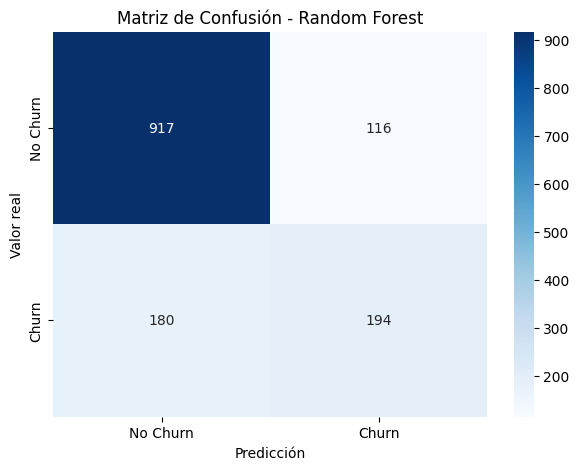

In [13]:
# Importar herramientas
from sklearn.metrics import confusion_matrix

# Calcular matriz de confusión
matriz = confusion_matrix(y_test, y_pred)

# Visualizar matriz de confusión
plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()


## Interpretación de resultados y conclusión

El modelo Random Forest obtuvo un Accuracy aproximado del 78,96%, esto nos permite entender que se clasificó correctamente gran parte de los clientes del conjunto de prueba.

La Precision fue del 62,58%, mientras que el Recall alcanzó un 51,87% y el F1-Score fue del 56,73%.

El Recall es la metrica mas importante para este tipo de predicción de churn, esto se debe a que nos permite identificar cual es la proporción de los clientes que abandonan realmente el servicio.

Mientras que en la matriz de confusión podemos ver 180 falsos negativos. Lo que explica es que el modelo no logra identificar a los 180 clientes que abandoraron realmente el servicio.

Lo que representa este tipo de esrrores es la perdida economica de la empresa, porque no les permite tomar medidas preventidas, ya sea ofrecer algún tipo de promoción o  beneficiones para poder contener a los clientes.

En conclusion, por mas que el modelo presenta un Accuarcy aceptable, se necesita mejorar el Recall para poder detectar una mayor cantidad de clientes que tengan riesgo de abandono.
